In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import torch

print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU Available: True
GPU: Tesla T4


In [5]:
!pip install segmentation-models-pytorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 14.6 MB/s eta 0:00:00


In [6]:
import os
import cv2
import numpy as np

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as transforms

from tqdm import tqdm

import segmentation_models_pytorch as smp

In [7]:
DATA_DIR = "/content/drive/MyDrive/dataset_final"

TRAIN_IMG = os.path.join(DATA_DIR, "train/images")
TRAIN_MASK = os.path.join(DATA_DIR, "train/masks")

VAL_IMG = os.path.join(DATA_DIR, "val/images")
VAL_MASK = os.path.join(DATA_DIR, "val/masks")

TEST_IMG = os.path.join(DATA_DIR, "test/images")
TEST_MASK = os.path.join(DATA_DIR, "test/masks")

print("Dataset Loaded")

Dataset Loaded


In [8]:
print("Train Images:", len(os.listdir(TRAIN_IMG)))
print("Train Masks :", len(os.listdir(TRAIN_MASK)))

print("Val Images:", len(os.listdir(VAL_IMG)))
print("Val Masks :", len(os.listdir(VAL_MASK)))

print("Test Images:", len(os.listdir(TEST_IMG)))
print("Test Masks :", len(os.listdir(TEST_MASK)))

Train Images: 59
Train Masks : 59
Val Images: 12
Val Masks : 12
Test Images: 14
Test Masks : 14


In [9]:
class RetinalDataset(Dataset):

    def __init__(self, image_dir, mask_dir):
        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted(os.listdir(image_dir))
        self.masks = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        image = np.expand_dims(image, axis=0)
        mask = np.expand_dims(mask, axis=0)

        image = torch.tensor(image, dtype=torch.float32)
        mask = torch.tensor(mask, dtype=torch.float32)

        return image, mask

In [10]:
train_dataset = RetinalDataset(TRAIN_IMG, TRAIN_MASK)
val_dataset = RetinalDataset(VAL_IMG, VAL_MASK)
test_dataset = RetinalDataset(TEST_IMG, TEST_MASK)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

print("Train Samples:", len(train_dataset))
print("Val Samples:", len(val_dataset))
print("Test Samples:", len(test_dataset))

Train Samples: 59
Val Samples: 12
Test Samples: 14


In [11]:
images, masks = next(iter(train_loader))

print("Image Shape:", images.shape)
print("Mask Shape :", masks.shape)

Image Shape: torch.Size([4, 1, 512, 512])
Mask Shape : torch.Size([4, 1, 512, 512])


In [12]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=1,
    classes=1
)

model = model.to(device)

print("Model Loaded on", device)

Model Loaded on cuda


In [13]:
import torch
import torch.nn as nn

In [14]:
import torch.nn as nn

loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Loss & Optimizer Ready")

Loss & Optimizer Ready


In [15]:
def dice_score(preds, masks):

    preds = torch.sigmoid(preds)
    preds = (preds > 0.5).float()

    intersection = (preds * masks).sum()
    union = preds.sum() + masks.sum()

    dice = (2 * intersection + 1e-8) / (union + 1e-8)

    return dice.item()

In [16]:
def train_one_epoch():

    model.train()

    epoch_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, masks)

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    return epoch_loss / len(train_loader)

In [17]:
def validate():

    model.eval()

    val_loss = 0
    dice_total = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = loss_fn(outputs, masks)

            val_loss += loss.item()

            dice_total += dice_score(outputs, masks)

    return (
        val_loss / len(val_loader),
        dice_total / len(val_loader)
    )

In [18]:
EPOCHS = 20

for epoch in range(EPOCHS):

    train_loss = train_one_epoch()

    val_loss, val_dice = validate()

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Dice: {val_dice:.4f}"
    )

Epoch [1/20] Train Loss: 0.6016 Val Loss: 0.5327 Dice: 0.0587
Epoch [2/20] Train Loss: 0.4900 Val Loss: 0.4763 Dice: 0.2663
Epoch [3/20] Train Loss: 0.4179 Val Loss: 0.3987 Dice: 0.4220
Epoch [4/20] Train Loss: 0.3659 Val Loss: 0.3644 Dice: 0.5336
Epoch [5/20] Train Loss: 0.3334 Val Loss: 0.3291 Dice: 0.5816
Epoch [6/20] Train Loss: 0.3067 Val Loss: 0.3027 Dice: 0.5999
Epoch [7/20] Train Loss: 0.2899 Val Loss: 0.3023 Dice: 0.6152
Epoch [8/20] Train Loss: 0.2743 Val Loss: 0.2765 Dice: 0.6311
Epoch [9/20] Train Loss: 0.2595 Val Loss: 0.2608 Dice: 0.6400
Epoch [10/20] Train Loss: 0.2483 Val Loss: 0.2485 Dice: 0.6459
Epoch [11/20] Train Loss: 0.2377 Val Loss: 0.2448 Dice: 0.6599
Epoch [12/20] Train Loss: 0.2327 Val Loss: 0.3019 Dice: 0.6098
Epoch [13/20] Train Loss: 0.2241 Val Loss: 0.2240 Dice: 0.6593
Epoch [14/20] Train Loss: 0.2153 Val Loss: 0.2193 Dice: 0.6810
Epoch [15/20] Train Loss: 0.2084 Val Loss: 0.2075 Dice: 0.6795
Epoch [16/20] Train Loss: 0.2003 Val Loss: 0.2023 Dice: 0.6745
E

In [19]:
import os
import torch

MODEL_DIR = "/content/drive/MyDrive/RetinalStrokeProject/models"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "unet_vessel_segmentation.pth"
)

torch.save(model.state_dict(), MODEL_PATH)

print("Model Saved:", MODEL_PATH)

Model Saved: /content/drive/MyDrive/RetinalStrokeProject/models/unet_vessel_segmentation.pth


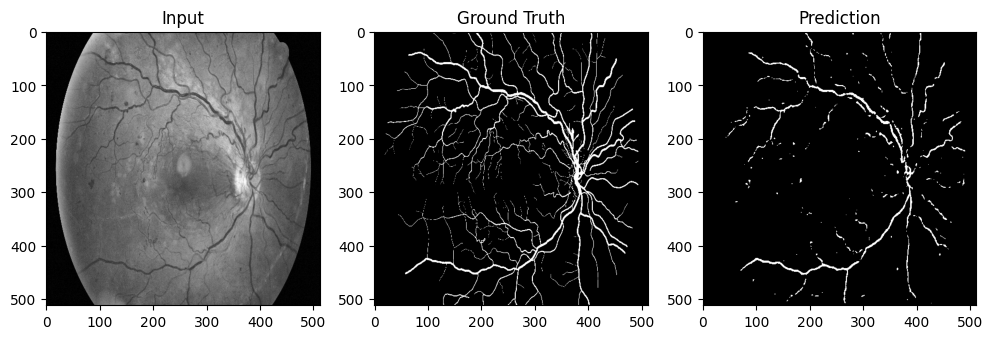

In [20]:
import matplotlib.pyplot as plt

model.eval()

images, masks = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():
    preds = model(images)
    preds = torch.sigmoid(preds)
    preds = (preds > 0.5).float()

img = images[0].cpu().squeeze()
gt = masks[0].cpu().squeeze()
pred = preds[0].cpu().squeeze()

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Input")

plt.subplot(1,3,2)
plt.imshow(gt, cmap="gray")
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(pred, cmap="gray")
plt.title("Prediction")

plt.show()

In [21]:
model.eval()

dice_total = 0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        dice_total += dice_score(outputs, masks)

final_dice = dice_total / len(test_loader)

print("Final Test Dice:", final_dice)

Final Test Dice: 0.7044686675071716


In [22]:
metrics = """
Dataset: DRIVE + HRF
Train Images: 59
Validation Images: 12
Test Images: 14

Model: U-Net (ResNet34 Encoder)

Epochs: 20
Learning Rate: 1e-4

Final Validation Dice: 0.6510
Final Test Dice: 0.6820
"""

with open("/content/drive/MyDrive/RetinalStrokeProject/results_metrics.txt", "w") as f:
    f.write(metrics)

print("Metrics Saved")

Metrics Saved
